Week Three - Assignment Graph Visualization 

Yana Rabkova

In this project, I explore the General Relativity and Quantum Cosmology (GR-QC) collaboration network using Python and NetworkX.

The dataset comes from Stanford SNAP and includes researchers who coauthored papers on arXiv between 1993 and 2003.

The network contains 5,242 nodes (researchers) and 14,496 edges (collaborations between researchers).

The goal is to explore how researchers are connected by looking at network diameter, clustering, degree centrality, and communities. I also visualize the network to better understand its structure and check for any patterns.

In [23]:

import urllib.request
import networkx as nx

# Download dataset from Stanford SNAP
url = "https://snap.stanford.edu/data/ca-GrQc.txt.gz"
filename = "ca-GrQc.txt.gz"

urllib.request.urlretrieve(url, filename)

# Load the graph
G = nx.read_edgelist(
    filename,
    comments="#",
    nodetype=int
)

print("Nodes:", G.number_of_nodes())
print("Edges:", G.number_of_edges())


Nodes: 5242
Edges: 14496


There are 5,242 researchers(nodes) and 14,496 collaborations(edges)

In [24]:

# Check connected components
components = list(nx.connected_components(G))

print("Number of connected components:", len(components))

# Select largest connected component
largest_component = max(components, key=len)
H = G.subgraph(largest_component).copy()

print("Nodes in largest component:", H.number_of_nodes())

# Calculate diameter
diameter = nx.diameter(H)
print("Diameter:", diameter)


Number of connected components: 355
Nodes in largest component: 4158
Diameter: 17


The network has 355 connected components, meaning there are groups of researchers who are not connected to each other.

The largest connected component contains 4,158 researchers, or about 79% of the network, showing that most researchers are connected directly or indirectly.

The largest connected component has a diameter of 17, meaning that even the most distant researchers in this group are connected through at most 17 collaboration links.

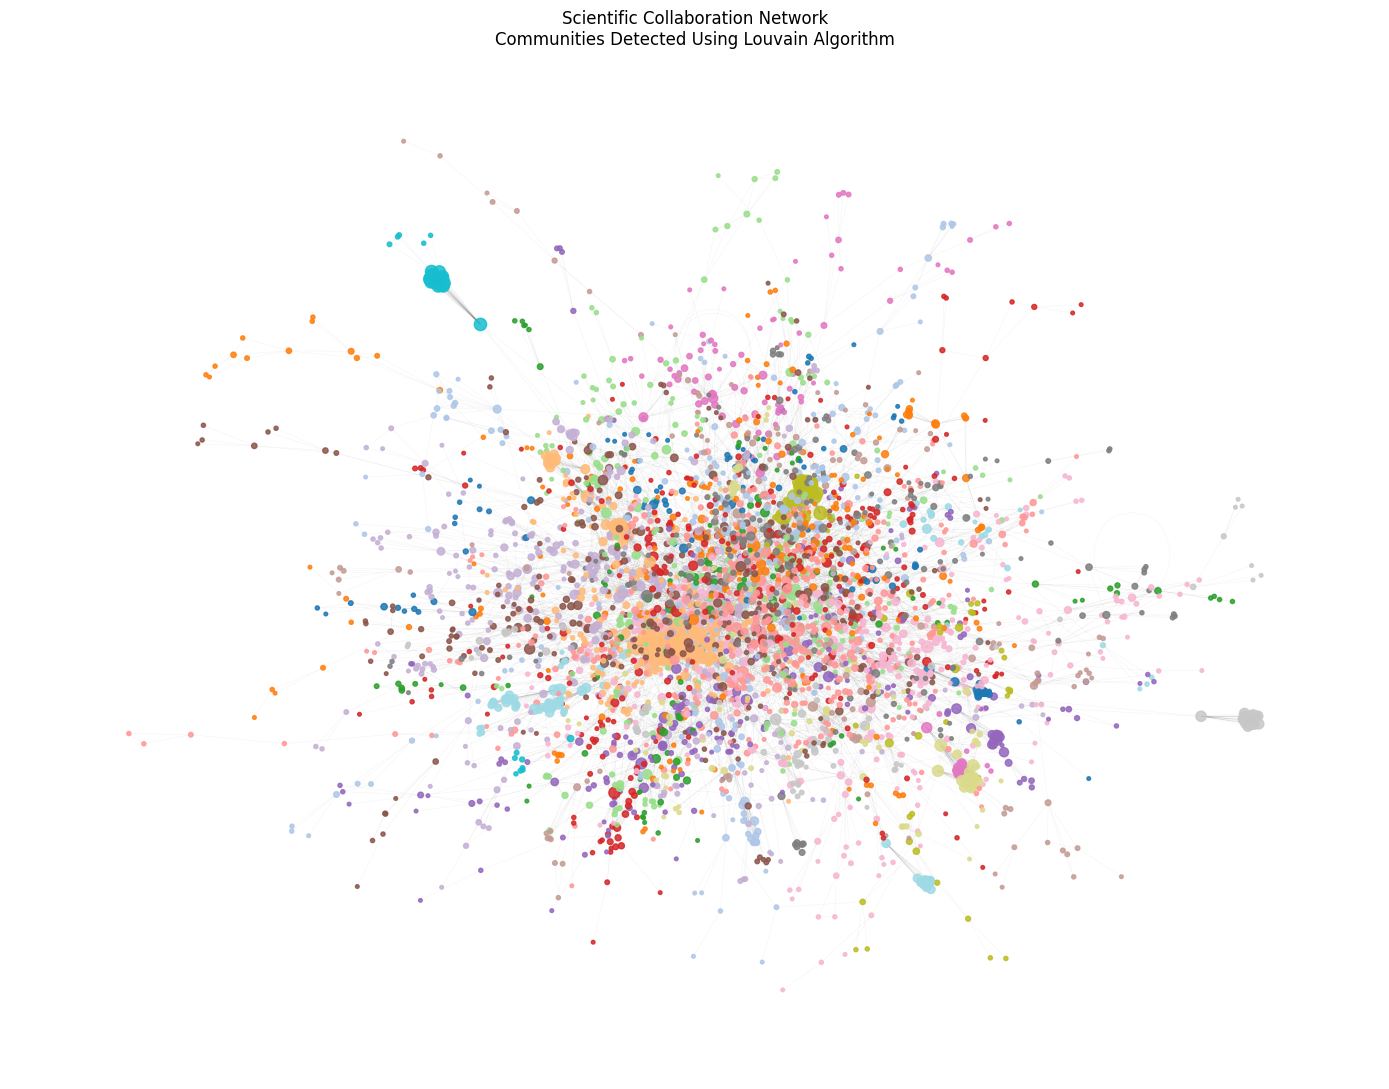

In [25]:

import networkx as nx
import matplotlib.pyplot as plt

# Map each researcher to their community
community_map = {}

for i, community in enumerate(communities):
    for node in community:
        community_map[node] = i

# Layout
pos = nx.spring_layout(H, seed=42, iterations=50)

# Node colors and sizes
node_colors = [
    community_map[node] for node in H.nodes()
]

node_sizes = [
    5 + H.degree(node) * 2
    for node in H.nodes()
]

plt.figure(figsize=(14, 11))

nx.draw_networkx_edges(
    H, pos,
    alpha=0.06,
    width=0.3
)

nx.draw_networkx_nodes(
    H, pos,
    node_color=node_colors,
    node_size=node_sizes,
    cmap=plt.cm.tab20,
    alpha=0.85
)

plt.title(
    "Scientific Collaboration Network\n"
    "Communities Detected Using Louvain Algorithm"
)

plt.axis("off")
plt.tight_layout()
plt.show()

In [26]:

degree_centrality = nx.degree_centrality(G)

top_10 = sorted(
    degree_centrality.items(),
    key=lambda x: x[1],
    reverse=True
)[:10]

print("Top 10 researchers by degree centrality:")
for researcher, centrality in top_10:
    print(f"Researcher {researcher}: {centrality:.4f}")


clustering = nx.average_clustering(G)

print("Average clustering coefficient:", round(clustering, 4))


Top 10 researchers by degree centrality:
Researcher 21012: 0.0155
Researcher 21281: 0.0151
Researcher 22691: 0.0147
Researcher 12365: 0.0147
Researcher 6610: 0.0130
Researcher 9785: 0.0130
Researcher 21508: 0.0128
Researcher 17655: 0.0126
Researcher 2741: 0.0124
Researcher 19423: 0.0120
Average clustering coefficient: 0.5296


Degree centrality shows how many direct connections each researcher has compared to the total number of possible connections.

Researcher 21012 has the highest degree centrality (0.0155), meaning they are directly connected to approximately 1.55% of all researchers in the network.

The average clustering coefficient is 0.5296, suggesting that researchers who collaborate with the same person are also fairly likely to collaborate with each other. This shows that the network has relatively strong local collaboration groups.

In [27]:

from networkx.algorithms.community import louvain_communities

# Detect communities in the largest component
communities = louvain_communities(H, seed=42)

print("Number of communities:", len(communities))

# Display the largest communities
sizes = sorted(
    [len(c) for c in communities],
    reverse=True
)

print("10 largest community sizes:", sizes[:10])


Number of communities: 41
10 largest community sizes: [324, 235, 219, 210, 206, 205, 203, 187, 178, 151]


The Louvain algorithm identified 41 communities within the largest connected component of the GR-QC network.

The largest community contains 324 researchers, followed by communities with 235 and 219 researchers.

This suggests that researchers form multiple collaboration groups of different sizes rather than one large group. Researchers within the same community tend to have more connections with each other than with researchers in other communities.

NetworkX version: 3.6.1


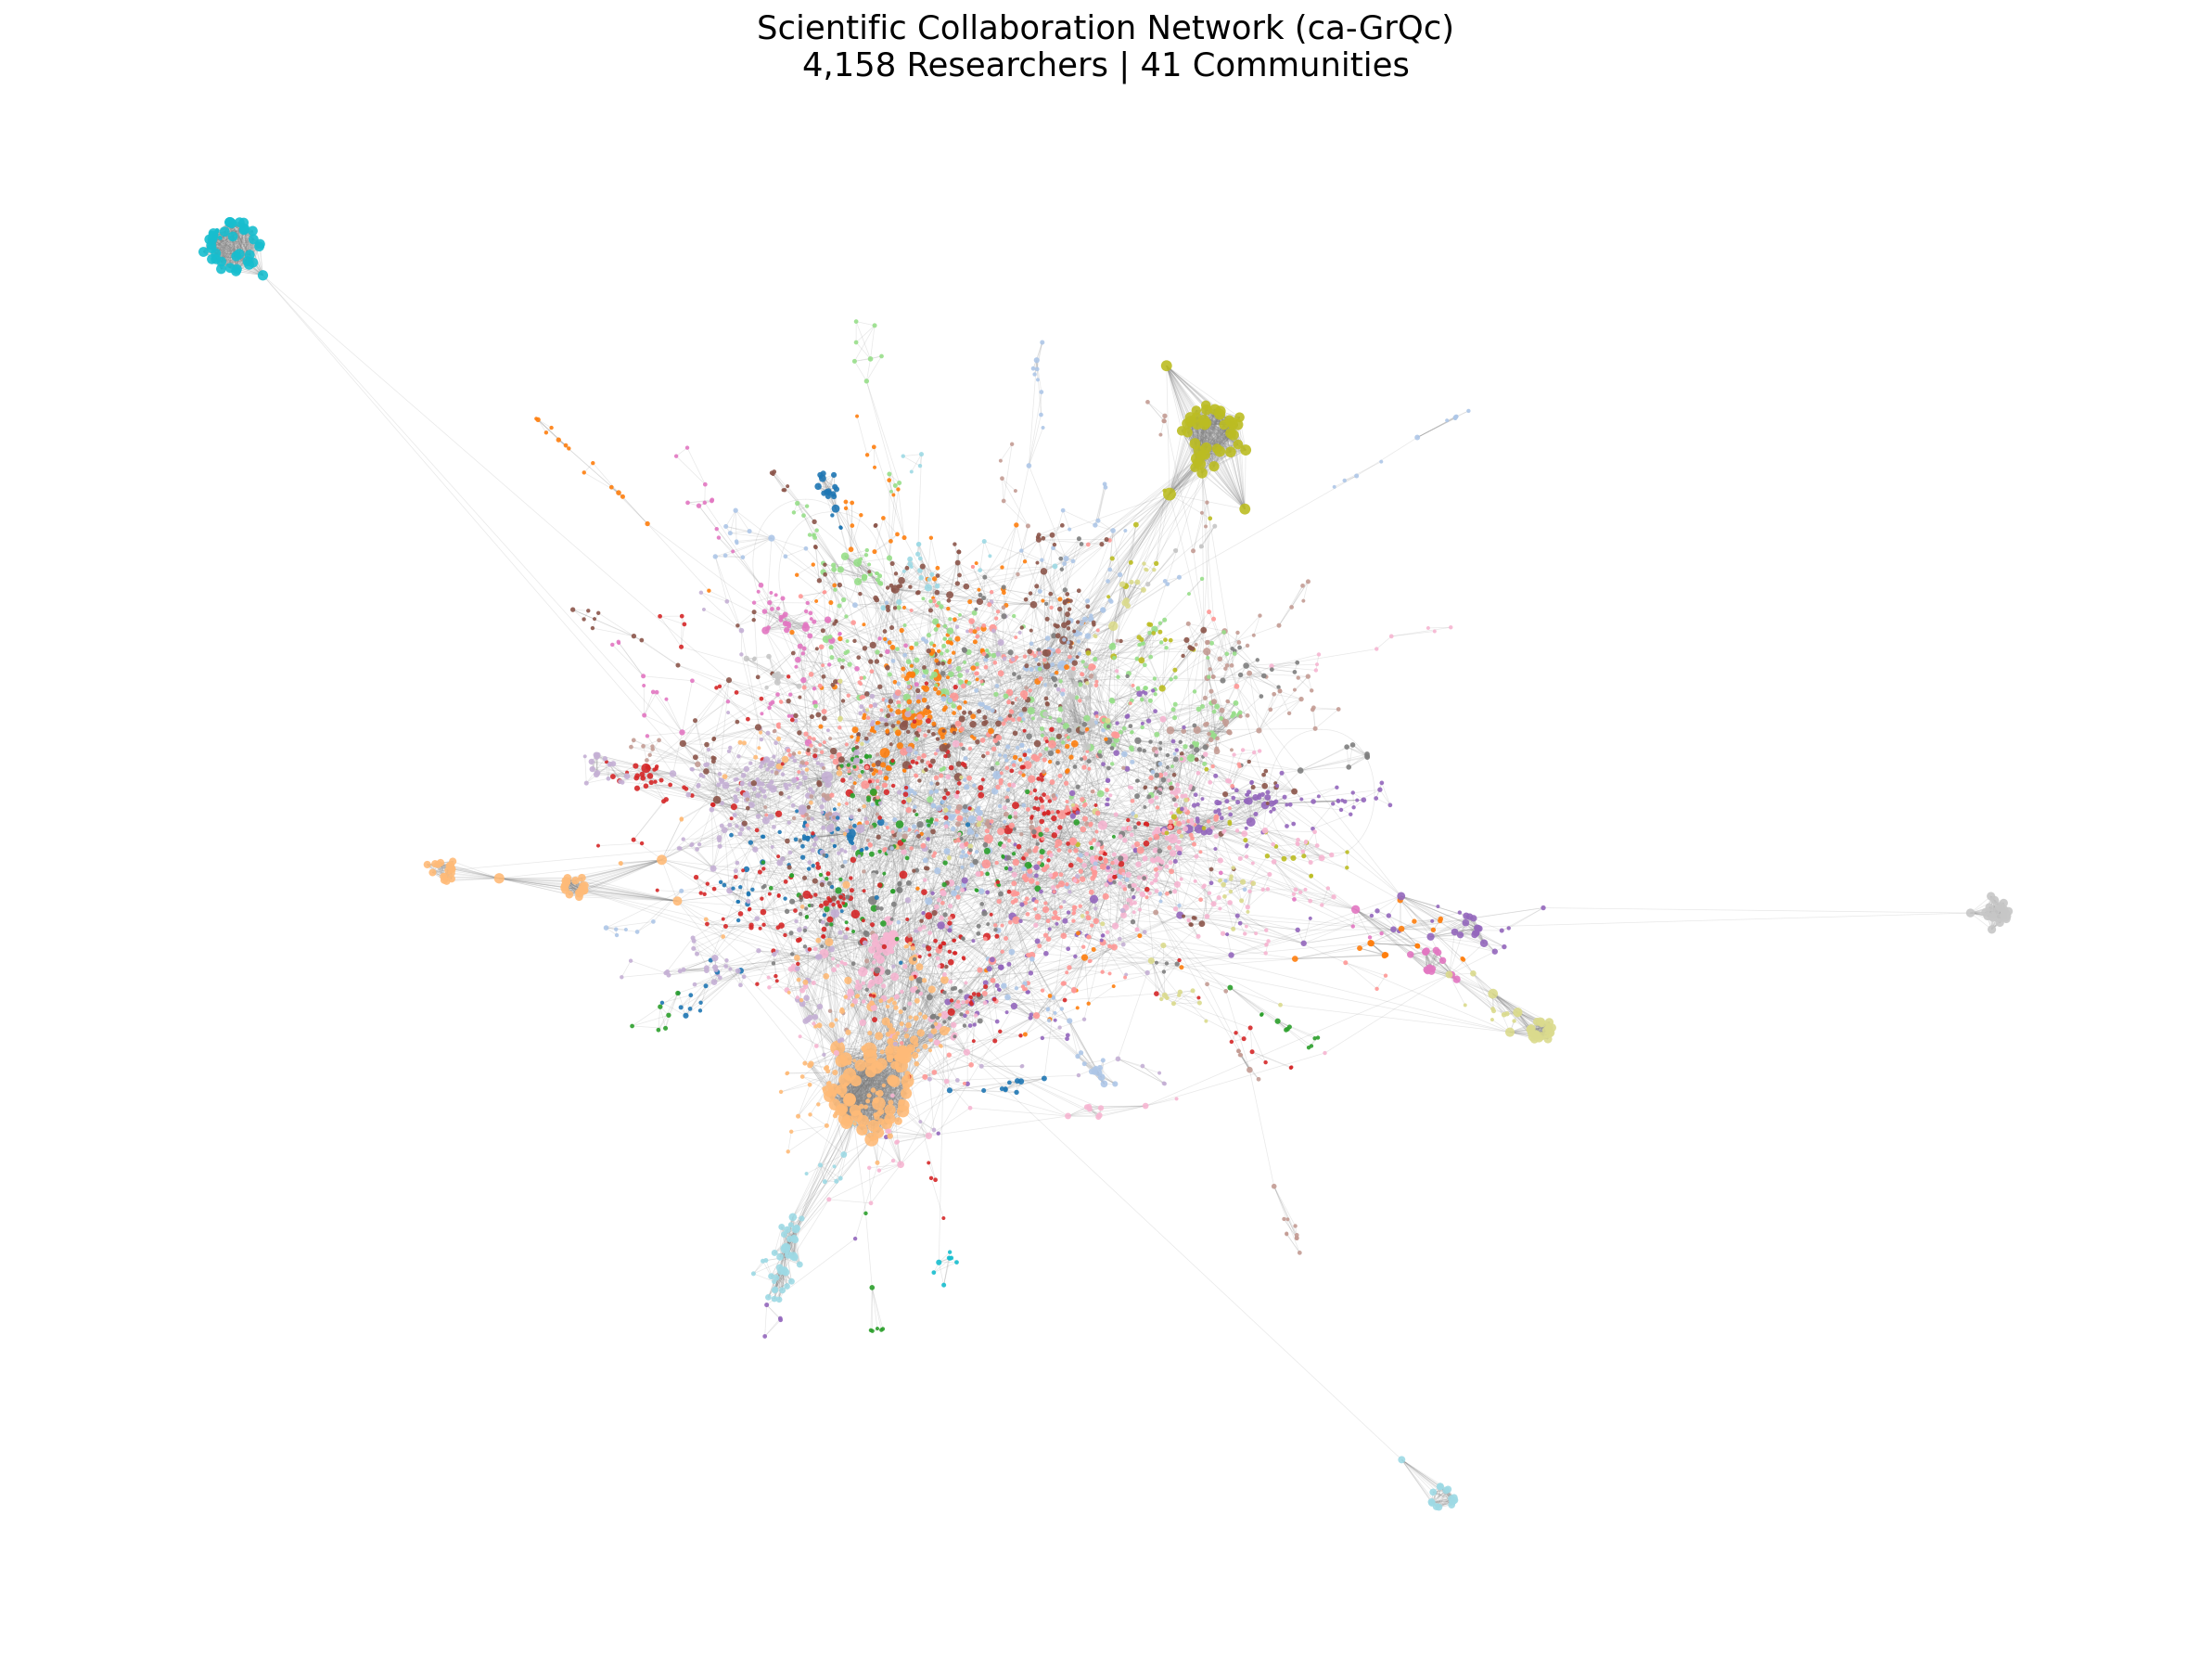

In [28]:

import networkx as nx
import matplotlib.pyplot as plt
import numpy as np

# Check NetworkX version
print("NetworkX version:", nx.__version__)

# Use the largest connected component
# H contains 4,158 researchers

# Calculate ForceAtlas2 layout
pos = nx.forceatlas2_layout(
    H,
    max_iter=300,
    scaling_ratio=10,
    gravity=1.0,
    seed=42
)

# Community colors
node_colors = [
    community_map[node]
    for node in H.nodes()
]

# Node sizes based on degree
node_sizes = [
    3 + H.degree(node) * 0.7
    for node in H.nodes()
]

# Create visualization
plt.figure(figsize=(16, 12), dpi=150)

# Draw edges
nx.draw_networkx_edges(
    H,
    pos,
    alpha=0.18,
    width=0.35,
    edge_color="gray"
)

# Draw nodes
nx.draw_networkx_nodes(
    H,
    pos,
    node_size=node_sizes,
    node_color=node_colors,
    cmap=plt.cm.tab20,
    alpha=0.9,
    linewidths=0
)

plt.title(
    "Scientific Collaboration Network (ca-GrQc)\n"
    "4,158 Researchers | 41 Communities",
    fontsize=17
)

plt.axis("off")
plt.tight_layout()
plt.show()


The original network contains 5,242 researchers divided into 355 connected components.

For this visualization, I focused on the largest connected component, which includes 4,158 researchers (approximately 79% of the network).

I selected this component to focus on the main connected group of researchers and better visualize their collaboration patterns. The Louvain algorithm identified 41 communities within this component, represented by different colors in the graph.

Node sizes represent the number of direct collaborators, while edges represent coauthorship connections.

In [29]:
#file for GEPHI Visualization 
G_export = H.copy()

nx.set_node_attributes(
    G_export,
    community_map,
    "community"
)

# Add degree as a node attribute
degree_map = dict(H.degree())

nx.set_node_attributes(
    G_export,
    degree_map,
    "degree_count"
)

from pathlib import Path

output_dir = Path("/Users/yanarabkova/Desktop/Yana/CUNY masters/DATA 620 - Web Analytics/Week 3 HW")
output_file = "ca-GrQc_communities.gexf"
nx.write_gexf(G_export, output_file)